In [ ]:
'''A Hybrid OpenMP-CUDA-MPI Pipeline for
Accelerating Knowledge Graph Construction from
Unstructured Text'''

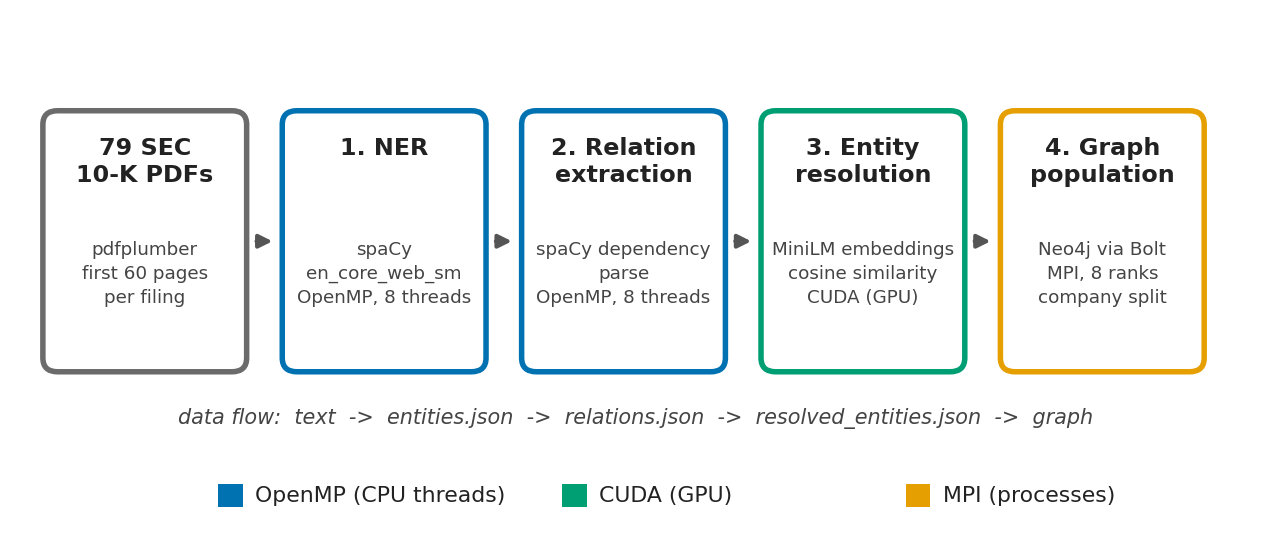

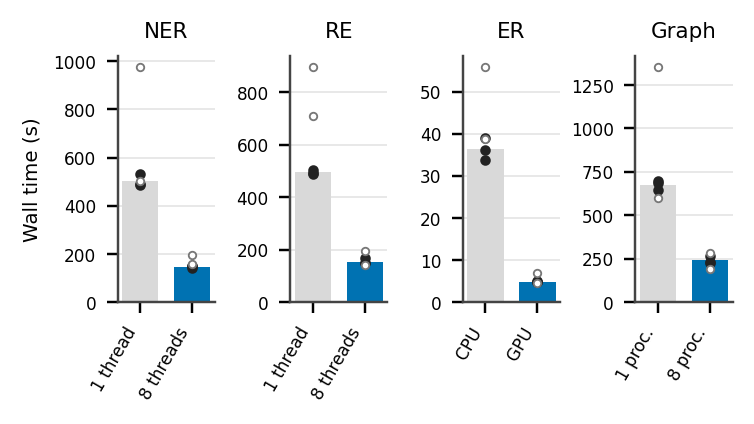

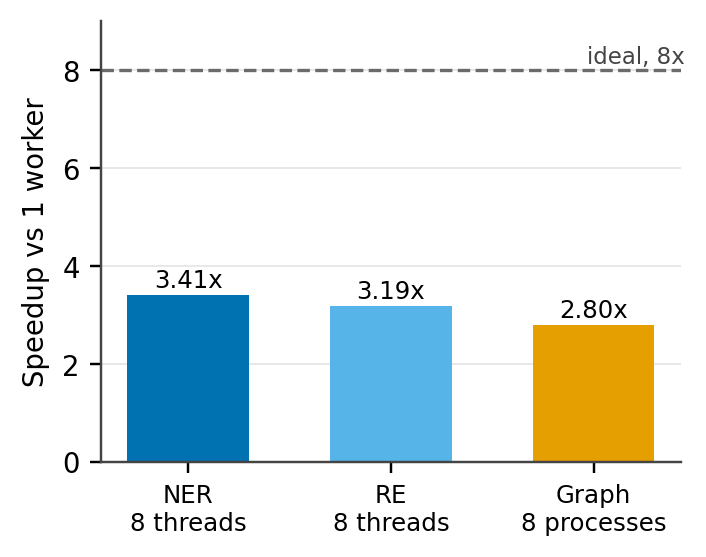

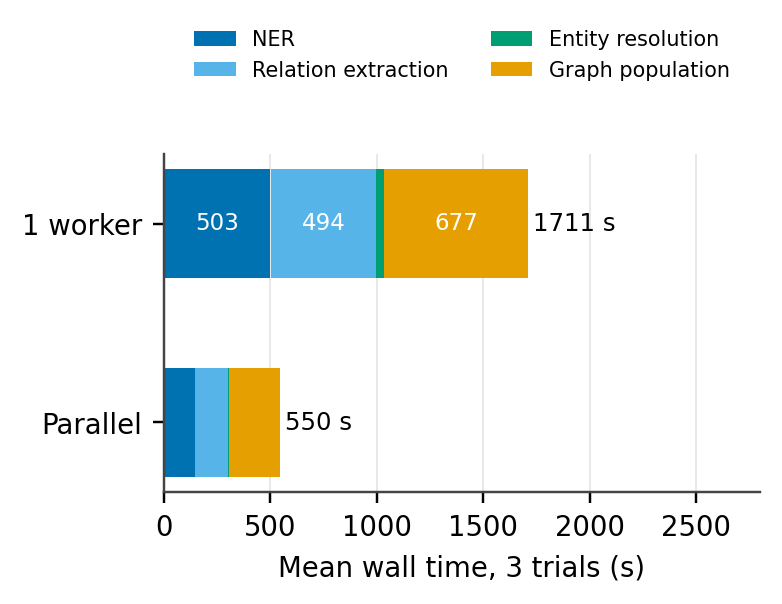

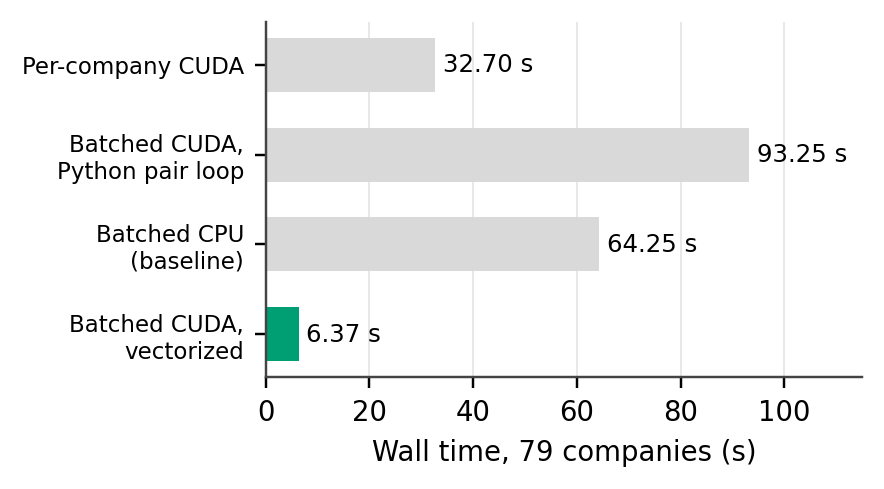

In [8]:
%matplotlib inline
import statistics as st
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

C = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73",
     "grey": "#6B6B6B", "light": "#D9D9D9", "sky": "#56B4E9"}

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#444", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
    "figure.dpi": 220, "savefig.bbox": "tight",
})

# ---------------- Figure 1: architecture flowchart ----------------
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.set_xlim(0, 100); ax.set_ylim(0, 44); ax.axis("off")
W, H, GAP, X0, Y0 = 16.0, 22.0, 3.5, 2.0, 14.0

def box(i, title, sub, color):
    x = X0 + i * (W + GAP)
    ax.add_patch(FancyBboxPatch((x, Y0), W, H, boxstyle="round,pad=0.3,rounding_size=1.2",
                                fc="white", ec=color, lw=1.8))
    ax.text(x + W / 2, Y0 + H - 2.0, title, ha="center", va="top",
            fontsize=7.8, fontweight="bold", color="#222", linespacing=1.2)
    ax.text(x + W / 2, Y0 + H - 11.0, sub, ha="center", va="top",
            fontsize=6.0, color="#444", linespacing=1.4)

box(0, "79 SEC\n10-K PDFs", "pdfplumber\nfirst 60 pages\nper filing", C["grey"])
box(1, "1. NER", "spaCy\nen_core_web_sm\nOpenMP, 8 threads", C["blue"])
box(2, "2. Relation\nextraction", "spaCy dependency\nparse\nOpenMP, 8 threads", C["blue"])
box(3, "3. Entity\nresolution", "MiniLM embeddings\ncosine similarity\nCUDA (GPU)", C["green"])
box(4, "4. Graph\npopulation", "Neo4j via Bolt\nMPI, 8 ranks\ncompany split", C["orange"])
for i in range(4):
    x1 = X0 + i * (W + GAP) + W + 0.6
    ax.add_patch(FancyArrowPatch((x1, Y0 + H / 2), (x1 + GAP - 1.2, Y0 + H / 2),
                                 arrowstyle="-|>", mutation_scale=9, lw=1.3, color="#555"))
ax.text(50, 9.2, "data flow:  text  ->  entities.json  ->  relations.json  ->  resolved_entities.json  ->  graph",
        ha="center", fontsize=6.8, color="#444", style="italic")
for i, (lab, col) in enumerate([("OpenMP (CPU threads)", C["blue"]),
                                ("CUDA (GPU)", C["green"]),
                                ("MPI (processes)", C["orange"])]):
    x = 16 + i * 28
    ax.add_patch(plt.Rectangle((x, 2.0), 2.0, 2.0, fc=col, ec="none"))
    ax.text(x + 3.0, 3.0, lab, va="center", fontsize=7.2, color="#222")
plt.show()

# ---------------- Figure 2: every trial ----------------
# (clean trials 1, 4, 5 as solid dots; excluded battery trials 2, 3 as hollow dots)
T = {
    "NER": ([532.578, 484.38, 491.571], [149.001, 143.063, 150.627], [503.059, 973.554], [158.071, 196.43], "1 thread", "8 threads"),
    "RE": ([493.075, 488.642, 501.387], [148.732, 149.338, 167.456], [892.89, 708.201], [196.218, 140.571], "1 thread", "8 threads"),
    "ER": ([39.020, 33.886, 36.150], [4.767, 4.852, 5.021], [38.713, 55.722], [4.594, 6.890], "CPU", "GPU"),
    "Graph": ([645.15, 688.26, 698.21], [230.43, 226.47, 269.05], [1350.38, 601.91], [283.42, 191.79], "1 proc.", "8 proc."),
}
fig, axes = plt.subplots(1, 4, figsize=(3.5, 2.0))
for ax, (name, (a, b, ex_a, ex_b, la, lb)) in zip(axes, T.items()):
    for x, vals, ex, col in [(0, a, ex_a, C["light"]), (1, b, ex_b, C["blue"])]:
        ax.bar(x, st.mean(vals), color=col, width=0.7)
        ax.scatter([x] * 3, vals, color="#222", s=6, zorder=3)
        ax.scatter([x] * len(ex), ex, facecolors="white", edgecolors="#777", s=6, linewidths=0.6, zorder=3)
    ax.set_xticks([0, 1]); ax.set_xticklabels([la, lb], rotation=60, fontsize=5.5, ha="right")
    ax.set_title(name, fontsize=7); ax.tick_params(axis="y", labelsize=5.5)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Wall time (s)", fontsize=6.5)
fig.tight_layout(w_pad=0.4)
plt.show()

# ---------------- Figure 3: speedup at 8 workers ----------------
fig, ax = plt.subplots(figsize=(3.4, 2.6))
vals = [3.41, 3.19, 2.80]
ax.bar(range(3), vals, color=[C["blue"], C["sky"], C["orange"]], width=0.6)
ax.axhline(8, color=C["grey"], ls="--", lw=1.1)
ax.text(2.45, 8.15, "ideal, 8x", ha="right", fontsize=7.5, color="#444")
for i, v in enumerate(vals):
    ax.text(i, v + 0.15, f"{v:.2f}x", ha="center", fontsize=8)
ax.set_xticks(range(3)); ax.set_xticklabels(["NER\n8 threads", "RE\n8 threads", "Graph\n8 processes"], fontsize=8)
ax.set_ylim(0, 9); ax.set_ylabel("Speedup vs 1 worker"); ax.grid(axis="x", visible=False)
plt.show()

# ---------------- Figure 4: where the time goes ----------------
seq = [("NER", 502.84), ("Relation extraction", 494.37), ("Entity resolution", 36.35), ("Graph population", 677.21)]
par = [147.56, 155.18, 4.88, 241.98]
fig, ax = plt.subplots(figsize=(3.5, 2.0))
cols = [C["blue"], C["sky"], C["green"], C["orange"]]
for row, (label, vals) in enumerate([("Parallel", par), ("1 worker", [v for _, v in seq])]):
    left = 0
    for v, c, (nm, _) in zip(vals, cols, seq):
        ax.barh(row, v - 1.5, left=left, color=c, height=0.55, label=nm if row == 0 else None)
        if v > 300:
            ax.text(left + v / 2, row, f"{v:.0f}", ha="center", va="center", fontsize=7.5, color="white")
        left += v
    ax.text(left + 20, row, f"{left:.0f} s", va="center", fontsize=8)
ax.set_yticks([0, 1]); ax.set_yticklabels(["Parallel", "1 worker"])
ax.set_xlim(0, 2800); ax.set_xlabel("Mean wall time, 3 trials (s)"); ax.grid(axis="y", visible=False)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.42), fontsize=6.8)
plt.show()

# ---------------- Figure 5: entity resolution progression ----------------
steps = [("Per-company CUDA", 32.70), ("Batched CUDA,\nPython pair loop", 93.25),
         ("Batched CPU\n(baseline)", 64.25), ("Batched CUDA,\nvectorized", 6.37)]
labels = [a for a, _ in steps][::-1]; vals = [b for _, b in steps][::-1]
fig, ax = plt.subplots(figsize=(3.5, 2.1))
ax.barh(labels, vals, color=[C["green"] if "vectorized" in l else C["light"] for l in labels], height=0.6)
ax.tick_params(axis="y", labelsize=7.5)
for i, v in enumerate(vals):
    ax.text(v + 1.5, i, f"{v:.2f} s", va="center", fontsize=8)
ax.set_xlim(0, 115); ax.set_xlabel("Wall time, 79 companies (s)"); ax.grid(axis="y", visible=False)
plt.show()